# 함정 9. 누산기 비트 폭과 포화

학습된 W4A8 단계별 QAT 체크포인트에서 누산기 폭만 바꾼다. 시드 0의 같은 테스트 이미지 1,000장으로 {12, 14, 16, 18, 24, 32}비트 × {포화, 랩}을 비교하고, 선택한 16·32비트 포화를 10,000장 전체에서 확인한다.

포화는 입력 채널 → 커널 행 → 커널 열 → bias 순서의 **매 덧셈**에 적용한다. 레이어별 비율은 최종 합만 검사하지 않고, 하나라도 범위를 넘은 누산 출력을 센다. 잔차 합과 pooling은 넓은 int64로 유지해 convolution/linear의 누산기 폭만 비교한다.

기존 FP32 fake-quant는 실수 bias와 잔차 합산을 사용하므로 일치 여부를 별도로 측정한다. 동일한 정수 bias·M0/n·반올림을 사용하는 float64 convolution 참조 경로와 32비트 정수 경로는 모든 경계 코드를 비교한다.

[구현과 규칙](../docs/README.md#함정-9-누산기-비트-폭과-포화), [재실행 스크립트](../scripts/run_m4.py).


In [1]:
from pathlib import Path
import json
import time
import platform
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from quant_pitfalls.sim.accumulator import AccumulatorSpec, accumulate, required_bits

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
STARTED = time.perf_counter()
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
from quant_pitfalls.results import load_results
DATA, DATA_SOURCE = load_results(ROOT, "m4")
print("Integer numerical input:", DATA_SOURCE)
assert DATA["state"] == "complete"
assert DATA["config"]["seed"] == SEED
print("Seed:", SEED, "Python:", platform.python_version(), "analysis torch:", torch.__version__)
print("Experiment environment:", DATA["environment"])
print("Experiment runtime (seconds):", round(DATA["runtime_seconds"], 3))
plt.rcParams.update({"svg.fonttype": "none", "svg.hashsalt": "quant-pitfalls-m4"})


Integer numerical input: docs/results/m4.json.gz
Seed: 0 Python: 3.11.15 analysis torch: 2.14.1+cu130
Experiment environment: {'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeForce RTX 5090'}
Experiment runtime (seconds): 151.699


## 덧셈 순서와 비트 폭

누산 순서와 비트 폭의 효과를 작은 입력으로 확인한다. 포화의 함수 합성 최적화도 순차 덧셈과 같은 결과를 내며, 포화 덧셈 자체를 재배열하지 않는다.


In [2]:
assert [required_bits(*values) for values in [(127, 255, 2304), (7, 255, 960), (7, 255, 9)]] == [28, 22, 15]
a, b = torch.tensor([100, 100, -100]), torch.tensor([100, -100, 100])
for mode in ("saturate", "wrap"):
    spec = AccumulatorSpec(8, mode)
    print(mode, accumulate(a, spec).item(), accumulate(b, spec).item())
assert accumulate(a, AccumulatorSpec(8)).item() == 27
assert accumulate(a, AccumulatorSpec(8), parallel=True).item() == 27


saturate 27 100
wrap 100 100


## 레이어별 코드 일치

`fixed_point_layers`에는 input, convolution의 누산 결과, 활성화, 잔차 경계, pooling, classifier가 포함된다. 기존 fake-quant와의 차이는 일치하는 것으로 숨기지 않는다.


In [3]:
parity = DATA["parity"]
assert parity["fixed_point_mismatches"] == 0
assert all(row["mismatches"] == 0 for row in parity["fixed_point_layers"])
print("Parity probe images:", parity["images"])
print("Fixed-point reference tensors:", len(parity["fixed_point_layers"]))
print("Fixed-point reference mismatches:", parity["fixed_point_mismatches"])
print("Original FP32 fake-quant mismatches:", parity["original_fake_quant_mismatches"])
print("Original logit max absolute difference:", parity["original_logit_max_abs_difference"])
print("Original prediction disagreements:", parity["original_prediction_disagreements"])
print("First original code differences:", [row for row in parity["original_fake_quant_layers"] if row["mismatches"]][:5])


Parity probe images: 32
Fixed-point reference tensors: 124
Fixed-point reference mismatches: 0
Original FP32 fake-quant mismatches: 8360767
Original logit max absolute difference: 1.4061174392700195
Original prediction disagreements: 0
First original code differences: [{'layer': 'features.0.2_output_quant', 'elements': 1048576, 'mismatches': 254}, {'layer': 'features.1.conv.0.2_output_quant', 'elements': 1048576, 'mismatches': 8372}, {'layer': 'features.1.conv.1_output_quant', 'elements': 524288, 'mismatches': 20822}, {'layer': 'features.1.output_quant', 'elements': 524288, 'mismatches': 20822}, {'layer': 'features.2.conv.0.2_output_quant', 'elements': 3145728, 'mismatches': 188528}]


## 정확도와 포화 비율

부분집합은 테스트셋의 첫 1,000장이다. 모든 설정에 같은 이미지를 사용하며, 전체 테스트 결과와 구분한다. 포화 비율에는 마지막 bias 덧셈도 포함한다.


In [4]:
bits = [12, 14, 16, 18, 24, 32]
rows = ["| Bits | Overflow | Images | Top-1 (%) |", "|---|---|---|---|"]
for width in bits:
    for mode in ("saturate", "wrap"):
        row = DATA["sweep"][f"{width}-{mode}"]
        rows.append(f"| {width} | {mode} | {row['images']} | {row['top1']:.2f} |")
display(Markdown("\n".join(rows)))
print("Original fake-quant subset top-1:", DATA["fake_quant_subset"]["top1"])
print("Original fake-quant full top-1:", DATA["fake_quant_full"]["top1"])
print("Full-test integer results:", {key: row["top1"] for key, row in DATA["full"].items()})


| Bits | Overflow | Images | Top-1 (%) |
|---|---|---|---|
| 12 | saturate | 1000 | 9.00 |
| 12 | wrap | 1000 | 11.30 |
| 14 | saturate | 1000 | 14.60 |
| 14 | wrap | 1000 | 8.90 |
| 16 | saturate | 1000 | 64.80 |
| 16 | wrap | 1000 | 11.60 |
| 18 | saturate | 1000 | 71.90 |
| 18 | wrap | 1000 | 9.80 |
| 24 | saturate | 1000 | 92.80 |
| 24 | wrap | 1000 | 92.80 |
| 32 | saturate | 1000 | 92.80 |
| 32 | wrap | 1000 | 92.80 |

Original fake-quant subset top-1: 92.8
Original fake-quant full top-1: 92.14
Full-test integer results: {'16-saturate': 65.59, '32-saturate': 92.18}


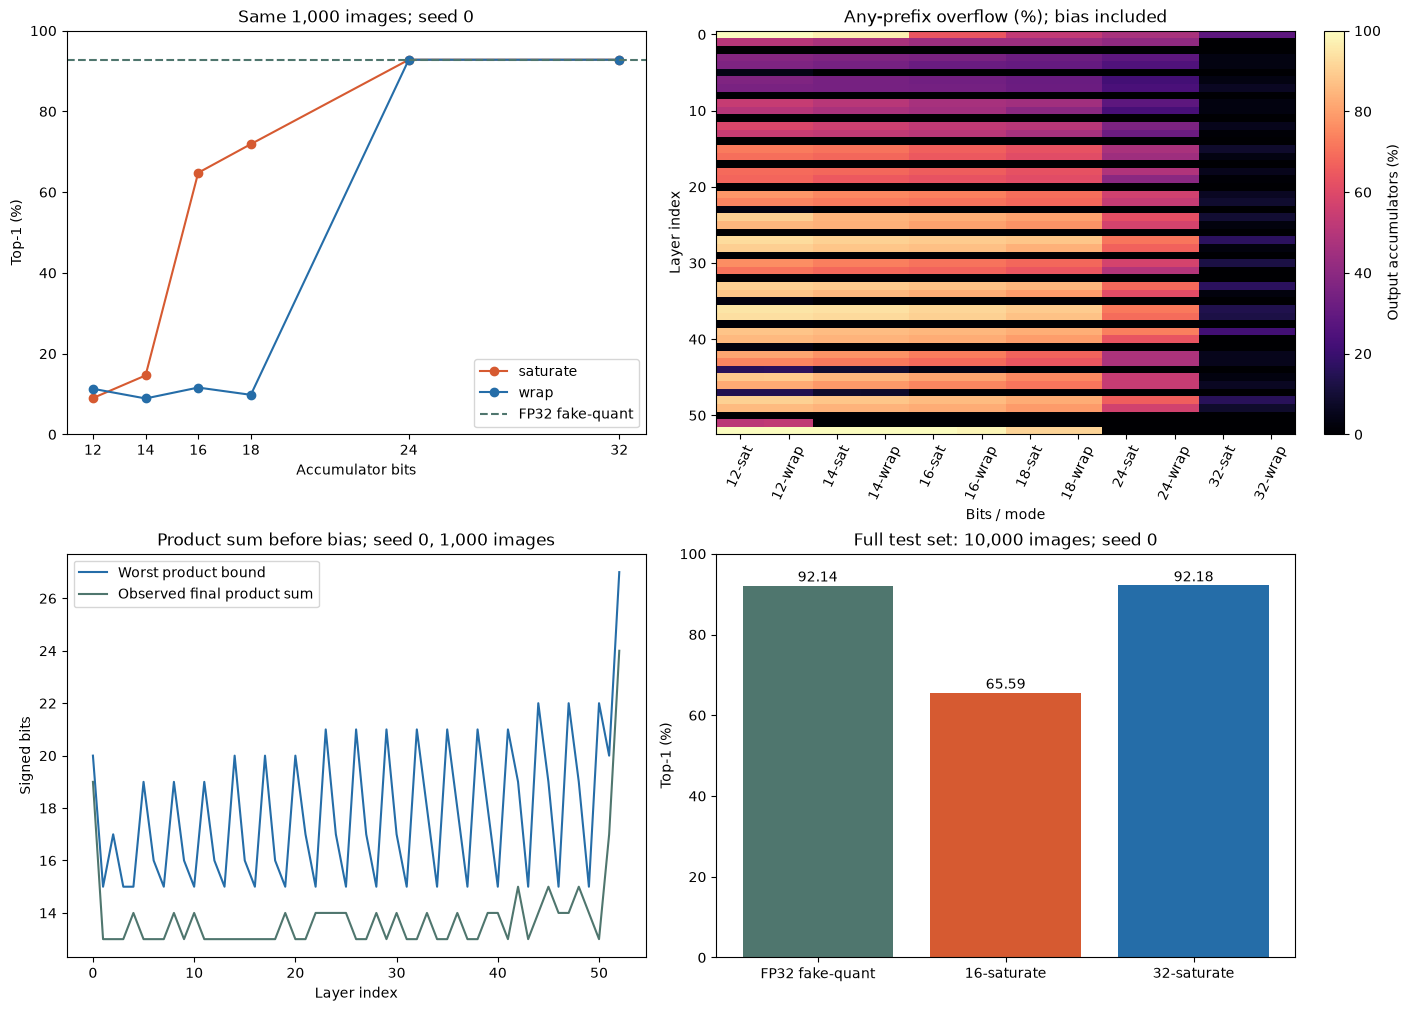

In [5]:
base = DATA["sweep"]["32-saturate"]["layers"]
names = list(base)
fig, axes = plt.subplots(2, 2, figsize=(14, 10), layout="constrained")
for mode, color in [("saturate", "#d65a31"), ("wrap", "#256da8")]:
    axes[0, 0].plot(bits, [DATA["sweep"][f"{b}-{mode}"]["top1"] for b in bits], "o-", label=mode, color=color)
axes[0, 0].axhline(DATA["fake_quant_subset"]["top1"], color="#4f766e", ls="--", label="FP32 fake-quant")
axes[0, 0].set(xlabel="Accumulator bits", ylabel="Top-1 (%)", title="Same 1,000 images; seed 0", xticks=bits, ylim=(0, 100))
axes[0, 0].legend()
keys = [f"{width}-{mode}" for width in bits for mode in ("saturate", "wrap")]
matrix = np.array([[DATA["sweep"][key]["layers"][name]["overflow_pct"] for key in keys] for name in names])
im = axes[0, 1].imshow(matrix, aspect="auto", interpolation="nearest", cmap="magma", vmin=0, vmax=100)
axes[0, 1].set(title="Any-prefix overflow (%); bias included", xlabel="Bits / mode", ylabel="Layer index", xticks=range(len(keys)), xticklabels=[key.replace("saturate", "sat") for key in keys])
axes[0, 1].tick_params(axis="x", rotation=65)
fig.colorbar(im, ax=axes[0, 1], label="Output accumulators (%)")
indices = np.arange(len(names))
axes[1, 0].plot(indices, [base[name]["required_bits"] for name in names], label="Worst product bound", color="#256da8")
axes[1, 0].plot(indices, [base[name]["max_abs_product_sum"].bit_length()+1 for name in names], label="Observed final product sum", color="#4f766e")
axes[1, 0].set(xlabel="Layer index", ylabel="Signed bits", title="Product sum before bias; seed 0, 1,000 images")
axes[1, 0].legend()
full_labels = ["FP32 fake-quant"] + list(DATA["full"])
full_scores = [DATA["fake_quant_full"]["top1"]] + [row["top1"] for row in DATA["full"].values()]
axes[1, 1].bar(full_labels, full_scores, color=["#4f766e", "#d65a31", "#256da8"][:len(full_labels)])
axes[1, 1].set(ylabel="Top-1 (%)", title="Full test set: 10,000 images; seed 0", ylim=(0, 100))
for index, score in enumerate(full_scores):
    axes[1, 1].text(index, score+1, f"{score:.2f}", ha="center")
figure = ROOT / "docs/figures/09_accumulator-saturation.svg"
fig.savefig(figure, metadata={"Date": None, "Creator": "quant-pitfalls"})
plt.show()


## 필요 비트와 실제 합

아래 표의 `Worst bits`는 가중치·활성화 코드 범위의 곱만 계산한 기존 식이다. `Observed product sum`은 포화시키기 전의 정확한 최종 곱 합이다. 작은 가중치 스케일에서는 정수 bias가 훨씬 커질 수 있으므로 별도로 표기한다. 최종 합이 범위 안에 있어도 중간 누산은 넘칠 수 있다는 점을 포화 비율에서 확인한다.


In [6]:
table = ["| Layer | Worst bits (products) | Observed product sum | Max bias code | Worst bits (+bias) | Observed sum (+bias) |", "|---|---|---|---|---|---|"]
for name, row in base.items():
    table.append(f"| {name} | {row['required_bits']} | {row['max_abs_product_sum']:,} | {row['bias_max']:,} | {row['required_bits_with_bias']} | {row['max_abs_sum']:,} |")
display(Markdown("\n".join(table)))
print("Analysis runtime (seconds):", round(time.perf_counter()-STARTED, 3))


| Layer | Worst bits (products) | Observed product sum | Max bias code | Worst bits (+bias) | Observed sum (+bias) |
|---|---|---|---|---|---|
| features.0.0 | 20 | 237,437 | 93,337,352,150 | 38 | 93,337,504,279 |
| features.1.conv.0.0 | 15 | 3,879 | 1,302,461,589 | 32 | 1,302,461,589 |
| features.1.conv.1 | 17 | 2,113 | 448 | 17 | 1,886 |
| features.2.conv.0.0 | 15 | 2,169 | 3,548,929,961 | 33 | 3,548,930,614 |
| features.2.conv.1.0 | 15 | 4,895 | 15,089,815,134 | 35 | 15,089,815,134 |
| features.2.conv.2 | 19 | 2,557 | 2,310 | 19 | 3,169 |
| features.3.conv.0.0 | 16 | 2,498 | 12,853,266,957 | 35 | 12,853,267,967 |
| features.3.conv.1.0 | 15 | 4,082 | 24,187,682,869 | 36 | 24,187,682,869 |
| features.3.conv.2 | 19 | 4,597 | 693 | 19 | 4,213 |
| features.4.conv.0.0 | 16 | 3,004 | 5,701,770,593 | 34 | 5,701,772,204 |
| features.4.conv.1.0 | 15 | 5,826 | 209,198,793,443 | 39 | 209,198,793,443 |
| features.4.conv.2 | 19 | 2,174 | 674 | 19 | 2,537 |
| features.5.conv.0.0 | 16 | 3,028 | 39,722,402,821 | 37 | 39,722,404,034 |
| features.5.conv.1.0 | 15 | 2,575 | 5,331,753,347 | 34 | 5,331,753,347 |
| features.5.conv.2 | 20 | 3,661 | 895 | 20 | 3,072 |
| features.6.conv.0.0 | 16 | 2,789 | 290,581,871,071 | 40 | 290,581,872,440 |
| features.6.conv.1.0 | 15 | 3,393 | 6,771,592,096 | 34 | 6,771,592,096 |
| features.6.conv.2 | 20 | 3,856 | 319 | 20 | 3,789 |
| features.7.conv.0.0 | 16 | 3,691 | 13,453,590,356 | 35 | 13,453,592,200 |
| features.7.conv.1.0 | 15 | 4,927 | 3,863,799,742 | 33 | 3,863,799,742 |
| features.7.conv.2 | 20 | 3,135 | 784 | 20 | 3,100 |
| features.8.conv.0.0 | 17 | 3,495 | 28,535,268,267 | 36 | 28,535,269,842 |
| features.8.conv.1.0 | 15 | 5,861 | 190,766,787,724 | 39 | 190,766,787,724 |
| features.8.conv.2 | 21 | 5,356 | 7,107 | 21 | 10,998 |
| features.9.conv.0.0 | 17 | 4,252 | 91,277,050,582 | 38 | 91,277,053,147 |
| features.9.conv.1.0 | 15 | 5,648 | 8,682,073,117 | 35 | 8,682,073,117 |
| features.9.conv.2 | 21 | 3,065 | 1,017 | 21 | 3,300 |
| features.10.conv.0.0 | 17 | 4,031 | 164,459,107,446 | 39 | 164,459,109,111 |
| features.10.conv.1.0 | 15 | 4,557 | 81,186,339,936 | 38 | 81,186,339,936 |
| features.10.conv.2 | 21 | 3,503 | 757 | 21 | 3,026 |
| features.11.conv.0.0 | 17 | 5,226 | 210,929,622,284 | 39 | 210,929,624,962 |
| features.11.conv.1.0 | 15 | 3,386 | 1,462,972,719 | 32 | 1,462,972,719 |
| features.11.conv.2 | 21 | 3,423 | 649 | 21 | 3,716 |
| features.12.conv.0.0 | 18 | 7,102 | 454,543,294,831 | 40 | 454,543,297,053 |
| features.12.conv.1.0 | 15 | 3,001 | 21,208,749,808 | 36 | 21,208,749,808 |
| features.12.conv.2 | 21 | 2,911 | 3,951 | 21 | 5,560 |
| features.13.conv.0.0 | 18 | 5,161 | 640,331,629,503 | 41 | 640,331,632,496 |
| features.13.conv.1.0 | 15 | 3,384 | 258,072,806,532 | 39 | 258,072,806,532 |
| features.13.conv.2 | 21 | 2,646 | 2,929 | 21 | 4,258 |
| features.14.conv.0.0 | 18 | 4,722 | 250,803,146,402 | 39 | 250,803,148,625 |
| features.14.conv.1.0 | 15 | 6,276 | 19,438,619,343 | 36 | 19,438,619,343 |
| features.14.conv.2 | 21 | 3,532 | 1,303 | 21 | 3,738 |
| features.15.conv.0.0 | 19 | 10,752 | 847,829,961,429 | 41 | 847,829,964,339 |
| features.15.conv.1.0 | 15 | 3,532 | 26,261,806,630 | 36 | 26,261,806,630 |
| features.15.conv.2 | 22 | 7,877 | 146,243 | 22 | 146,243 |
| features.16.conv.0.0 | 19 | 10,196 | 179,434,006,319 | 39 | 179,434,008,135 |
| features.16.conv.1.0 | 15 | 5,689 | 12,639,729,776 | 35 | 12,639,729,776 |
| features.16.conv.2 | 22 | 5,169 | 31,076 | 22 | 33,573 |
| features.17.conv.0.0 | 19 | 8,514 | 6,056,939,291,051 | 44 | 6,056,939,294,947 |
| features.17.conv.1.0 | 15 | 6,227 | 54,338,065,016,363 | 47 | 54,338,065,016,363 |
| features.17.conv.2 | 22 | 3,966 | 627 | 22 | 3,842 |
| features.18.0 | 20 | 37,528 | 1,977 | 20 | 38,763 |
| classifier.1 | 27 | 4,224,197 | 20,072 | 27 | 4,244,269 |

Analysis runtime (seconds): 0.809


## 직접 확인하기

8비트 폭을 고정하고 [100, 100, −100]의 덧셈 순서만 바꿔 보자. 포화와 wrap의 결과를 손으로 계산한 뒤 위 코드와 비교하자.
